# Program 16: the forget signature

**What:** before deleting a class, record the main directions its features occupy.

**How:** pass the class's buffer samples through the network and collect penultimate features (512-dim for ResNet-18). Center them and run PCA. Keep the top k directions as a 512×k matrix U_c (start with k = 5). Also print how much variance those k directions explain.

**Why:** this small matrix is the only thing you keep after deleting the data. It lets you guard against the class returning without storing any of its images.

**Understanding note:** a class lives in a few directions of feature space. If later learning stops rebuilding those directions, the class can't come back.

**Done when:** you can save and reload U_c, and a handful of directions explain a large share of the class's feature variance.

## Where this fits (for a first-time reader)

This is the first piece of **our method, Relapse-Guard**. Phase D showed that forgotten classes can come back, and that the features may still hold them (programs 14, 15). The full method will add a **guard loss** during all later learning:

$$\mathcal{L} = \underbrace{\text{DER++ loss}}_{\text{learn new tasks, keep old ones}} \;+\; \lambda \sum_{c\,\in\,\text{forgotten}} \big\lVert U_c^{\top} h(x) \big\rVert^2$$

- h(x) = the 512 features of an image (program 14).
- **U_c = the forget signature of class c**: k directions in the 512-dim feature space where class c's features vary the most. This program builds it.
- The guard term is large when an image's features point along those directions. Penalizing it stops later learning from **rebuilding** the forgotten class's feature directions (program 18).

**Why a few directions?** The 512 features of all wolf images don't fill the whole 512-dim space. They spread mostly along a few directions (for example "fur texture", "pointed ears", "grey colour"). PCA (principal component analysis) finds those directions, ordered by how much of the spread each explains.

**Privacy:** after deletion we may keep U_c (512 × 5 = 2,560 numbers) but no wolf image. Five averaged directions can't be turned back into a specific photo.

**The model used:** program 15's seed-0 model right **before** `U wolf` (`results/15_before_unlearn.pt`), with its DER++ buffer. That is exactly the moment the signature must be recorded: the class is still known and its buffer images still exist.

## 1. Setup

In [1]:
import gc, sys, time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "common").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))  # lets us import common/

# Reload the shared code, so edits to common/ are picked up even without restarting the kernel.
import importlib
import common.utils, common.data, common.models, common.train, common.derpp, common.badteacher, common.features, common.metrics
for module in (common.utils, common.data, common.models, common.train, common.derpp, common.badteacher, common.features, common.metrics):
    importlib.reload(module)

import matplotlib.pyplot as plt
import numpy as np
import torch

from common.data import SplitCIFAR100
from common.features import features_of
from common.models import resnet18_cifar
from common.utils import RESULTS_DIR, get_device, log_run

SETTINGS = {
    "k": 5,                 # directions kept in the signature
    "k_max_plot": 30,       # how many components to show in the variance plot
}
device = get_device()

ck_path = RESULTS_DIR / "15_before_unlearn.pt"
if not ck_path.exists():
    raise FileNotFoundError(f"{ck_path} not found. Run program 15 first.")
ck = torch.load(ck_path, map_location="cpu", weights_only=False)
A, WOLF = np.array(ck["labels"]["A"]), ck["labels"]["WOLF"]

data = SplitCIFAR100(seed=0, batch_size=128, num_workers=0)
NAMES = data.class_names
model = resnet18_cifar(num_classes=100).to(device)
model.load_state_dict(ck["model"])
model.eval()
buf = ck["buffer"]
n = buf["n_kept"]
buf_idx, buf_lab = buf["indices"][:n], buf["labels"][:n]
print(f"model: program 15, seed 0, after learning task A, before U wolf")
print("buffer images per task-A class:", {NAMES[c]: int((buf_lab == c).sum()) for c in A})

model: program 15, seed 0, after learning task A, before U wolf
buffer images per task-A class: {'wolf': 203, 'camel': 200, 'cattle': 204, 'chimpanzee': 171, 'elephant': 213, 'kangaroo': 221, 'bus': 219, 'bicycle': 185, 'orchid': 198, 'apple': 186}


## 2. Features of the class's buffer images

The buffer images are loaded **without augmentation** (no random crop or flip), so the features describe the images themselves.

In [2]:
def buffer_features(label):
    idx = buf_idx[buf_lab == label]
    X = torch.stack([data.train_set_plain[j][0] for j in idx]).to(device)
    return features_of(model, X).numpy()


H_wolf = buffer_features(WOLF)
print(f"wolf: {H_wolf.shape[0]} buffer images -> features {H_wolf.shape}")
print(f"features are non-negative (after ReLU): min {H_wolf.min():.3f}, mean {H_wolf.mean():.3f}")

wolf: 203 buffer images -> features (203, 512)
features are non-negative (after ReLU): min 0.000, mean 0.201


## 3. PCA: the signature

1. **Center:** subtract the class's mean feature vector μ_c, so PCA describes how wolf images *vary*, not where they sit on average.
2. **SVD** of the centered features gives the principal directions, sorted by how much variance each explains.
3. **U_c** = the top k directions as columns: a 512 × k matrix with orthonormal columns (each has length 1, and they are at right angles to each other).

How to read the numbers: if wolf's features were spread evenly in all directions, k = 5 directions out of about 200 possible (the number of images limits the rank) would explain only about 5/200 = 2.5% of the variance. Much more than that means the class really lives in a few directions.

In [3]:
def signature(H, k):
    mu = H.mean(0)
    _, S, Vt = np.linalg.svd(H - mu, full_matrices=False)
    ratio = S**2 / (S**2).sum()
    return Vt[:k].T, mu, ratio        # U: [512, k]


K = SETTINGS["k"]
U_wolf, mu_wolf, ratio_wolf = signature(H_wolf, K)
cum = np.cumsum(ratio_wolf)
print("variance explained by each of the first 10 directions (%):")
print("  " + " ".join(f"{v*100:5.1f}" for v in ratio_wolf[:10]))
for k in (1, 3, 5, 10, 20):
    print(f"  top {k:2d} directions: {cum[k-1]*100:5.1f}% of wolf's feature variance "
          f"(evenly spread would give {k/len(ratio_wolf)*100:4.1f}%)")
print(f"\nU_wolf: {U_wolf.shape}, columns orthonormal: {np.allclose(U_wolf.T @ U_wolf, np.eye(K), atol=1e-5)}")

variance explained by each of the first 10 directions (%):
   25.1  23.5  14.5   6.3   4.7   4.3   3.5   2.3   1.5   1.3
  top  1 directions:  25.1% of wolf's feature variance (evenly spread would give  0.5%)
  top  3 directions:  63.1% of wolf's feature variance (evenly spread would give  1.5%)
  top  5 directions:  74.1% of wolf's feature variance (evenly spread would give  2.5%)
  top 10 directions:  86.9% of wolf's feature variance (evenly spread would give  4.9%)
  top 20 directions:  92.3% of wolf's feature variance (evenly spread would give  9.9%)

U_wolf: (512, 5), columns orthonormal: True


## 4. Save and reload (the "Done when" check)

The signature file holds U_c, μ_c and the explained-variance numbers, and no image. Reloading must give back exactly the same matrix.

In [4]:
sig_path = RESULTS_DIR / f"16_signature_{NAMES[WOLF]}.pt"
torch.save({"U": torch.from_numpy(U_wolf.astype(np.float32)), "mean": torch.from_numpy(mu_wolf.astype(np.float32)),
            "explained": torch.from_numpy(ratio_wolf[:K].astype(np.float32)), "label": WOLF, "name": NAMES[WOLF],
            "k": K, "n_images": int(H_wolf.shape[0]), "source": "15_before_unlearn.pt"}, sig_path)
loaded = torch.load(sig_path)
same = torch.allclose(loaded["U"], torch.from_numpy(U_wolf.astype(np.float32)))
print(f"saved {sig_path.name} ({sig_path.stat().st_size / 1024:.1f} KB): U {tuple(loaded['U'].shape)}, "
      f"k={loaded['k']}, from {loaded['n_images']} images")
print("identical after reload:", same)
assert same

saved 16_signature_wolf.pt (14.2 KB): U (512, 5), k=5, from 203 images
identical after reload: True


## 5. Is it just wolf, or does every class look like this?

The same PCA for all 10 task-A classes, from their buffer images. Left: the cumulative variance explained by the top k directions, one line per class. Right: how much the signatures of two classes **overlap**: $\lVert U_a^\top U_b\rVert_F^2 / k$, which is 1 if the two classes use exactly the same directions and 0 if they share none.

Overlap matters for the guard. If wolf's directions are also used by camel or cattle (kept classes), penalizing them would also hurt those classes: that's **spill** caused by the guard. Program 19 will need to deal with it.

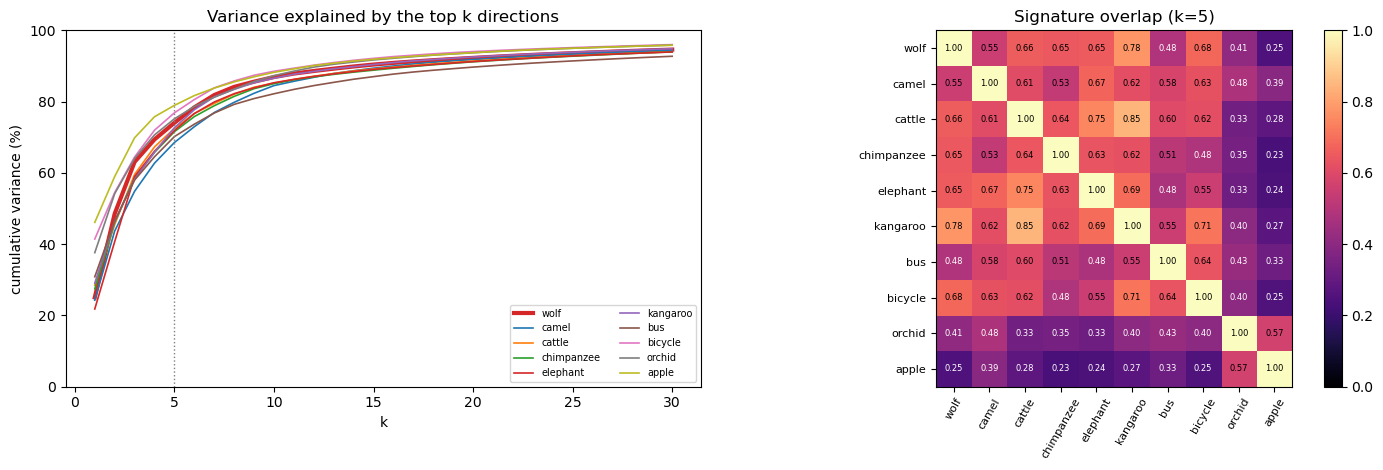

top-5 variance explained: wolf 74%, camel 69%, cattle 72%, chimpanzee 72%, elephant 72%, kangaroo 73%, bus 70%, bicycle 77%, orchid 75%, apple 79%
wolf's largest overlap with another class: kangaroo (0.78)


In [5]:
SIGS, RATIOS = {}, {}
for c in A:
    H = buffer_features(c)
    SIGS[c], _, RATIOS[c] = signature(H, K)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ax = axes[0]
kk = np.arange(1, SETTINGS["k_max_plot"] + 1)
for c in A:
    ax.plot(kk, np.cumsum(RATIOS[c])[:len(kk)] * 100, lw=3 if c == WOLF else 1.2,
            color="tab:red" if c == WOLF else None, label=NAMES[c])
ax.axvline(K, color="gray", ls=":", lw=1)
ax.set(title="Variance explained by the top k directions", xlabel="k", ylabel="cumulative variance (%)", ylim=(0, 100))
ax.legend(fontsize=7, ncol=2)

ax = axes[1]
overlap = np.array([[np.linalg.norm(SIGS[a].T @ SIGS[b]) ** 2 / K for b in A] for a in A])
im = ax.imshow(overlap, vmin=0, vmax=1, cmap="magma")
ax.set_xticks(range(len(A)), [NAMES[c] for c in A], rotation=60, fontsize=8)
ax.set_yticks(range(len(A)), [NAMES[c] for c in A], fontsize=8)
for i in range(len(A)):
    for j in range(len(A)):
        ax.text(j, i, f"{overlap[i, j]:.2f}", ha="center", va="center", fontsize=6,
                color="white" if overlap[i, j] < 0.5 else "black")
ax.set_title(f"Signature overlap (k={K})")
fig.colorbar(im, ax=ax, fraction=0.04)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "16_signatures.png", dpi=120)
plt.show()

wi = list(A).index(WOLF)
print(f"top-{K} variance explained: " + ", ".join(f"{NAMES[c]} {np.cumsum(RATIOS[c])[K-1]*100:.0f}%" for c in A))
print(f"wolf's largest overlap with another class: {NAMES[A[np.argsort(overlap[wi])[-2]]]} "
      f"({np.sort(overlap[wi])[-2]:.2f})")

## 6. Does the signature pick out wolf images?

For test images of each task-A class, we measure how much of an image's feature vector lies along wolf's signature:

$$\text{share}(x) = \frac{\lVert U_{\text{wolf}}^\top (h(x) - m) \rVert^2}{\lVert h(x) - m \rVert^2}$$

where m is the average feature of all task-A test images. (Without subtracting m, every image would score high: all features are non-negative after ReLU, so they share one big common direction. This is a design choice for the guard loss in program 18: penalize ‖U_cᵀ h(x)‖² as the roadmap writes, or the centered version used here.)

If the signature is specific to wolf, wolf test images should have a clearly higher share than the other classes.

In [6]:
targets = np.array(data.test_set.targets)
test_idx = np.where(np.isin(targets, A))[0]
X_test = torch.stack([data.test_set[i][0] for i in test_idx]).to(device)
Y_test = targets[test_idx]


def share(H, U, m):
    D = H - m
    return (np.linalg.norm(D @ U, axis=1) ** 2) / (np.linalg.norm(D, axis=1) ** 2 + 1e-12)


H_test = features_of(model, X_test).numpy()
m_ref = H_test.mean(0)
shares = {c: share(H_test[Y_test == c], U_wolf, m_ref) for c in A}
for c in A:
    print(f"{NAMES[c]:>12}: share on wolf's signature {shares[c].mean()*100:5.1f}%"
          + ("   <- wolf" if c == WOLF else ""))
print(f"\nrandom {K} directions would give about {K/512*100:.1f}%")

        wolf: share on wolf's signature  69.9%   <- wolf
       camel: share on wolf's signature  49.4%
      cattle: share on wolf's signature  52.7%
  chimpanzee: share on wolf's signature  69.0%
    elephant: share on wolf's signature  63.0%
    kangaroo: share on wolf's signature  66.2%
         bus: share on wolf's signature  48.7%
     bicycle: share on wolf's signature  54.8%
      orchid: share on wolf's signature  57.5%
       apple: share on wolf's signature  19.4%

random 5 directions would give about 1.0%


## 7. A first look at relapse through the signature

Program 15 saved its seed-0 models: right after `U wolf`, and after each of the 4 later-learning conditions. For each model we compute the wolf test images' share on the **stored** signature (recorded before `U`, and never updated). This is what the guard will watch during later learning.

- After `U`, the share should fall (unlearning moved wolf's features off those directions).
- If later learning **rebuilds** wolf's directions, the share rises again, and should rise most where program 15 saw the most relapse.

As a control, the other task-A classes' average share is shown too. m (the reference mean) is recomputed for each model.

                before U: wolf share  69.9%   other task-A classes  53.4%


                 after U: wolf share  31.0%   other task-A classes  39.4%


    end: purged, similar: wolf share  21.1%   other task-A classes  16.7%


 end: purged, dissimilar: wolf share  15.2%   other task-A classes  18.8%


      end: kept, similar: wolf share  23.8%   other task-A classes  15.6%


   end: kept, dissimilar: wolf share  25.3%   other task-A classes  21.5%


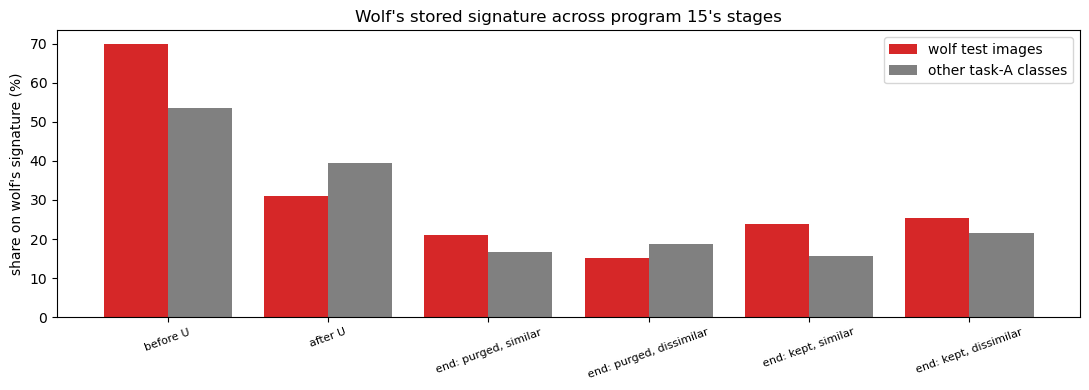

In [7]:
stages = [("before U", ck["model"])]
for name, file in [("after U", "15_after_unlearn_model.pt"),
                   ("end: purged, similar", "15_purged_similar_model.pt"),
                   ("end: purged, dissimilar", "15_purged_dissimilar_model.pt"),
                   ("end: kept, similar", "15_kept_similar_model.pt"),
                   ("end: kept, dissimilar", "15_kept_dissimilar_model.pt")]:
    if (RESULTS_DIR / file).exists():
        stages.append((name, torch.load(RESULTS_DIR / file, map_location="cpu")))

track = {}
for name, state in stages:
    model.load_state_dict(state)
    H = features_of(model, X_test).numpy()
    m = H.mean(0)
    wolf_share = share(H[Y_test == WOLF], U_wolf, m).mean()
    other_share = share(H[Y_test != WOLF], U_wolf, m).mean()
    track[name] = (float(wolf_share), float(other_share))
    print(f"{name:>24}: wolf share {wolf_share*100:5.1f}%   other task-A classes {other_share*100:5.1f}%")

fig, ax = plt.subplots(figsize=(11, 4))
names = list(track)
ax.bar(np.arange(len(names)) - 0.2, [track[n][0] * 100 for n in names], 0.4, label="wolf test images", color="tab:red")
ax.bar(np.arange(len(names)) + 0.2, [track[n][1] * 100 for n in names], 0.4, label="other task-A classes", color="gray")
ax.set_xticks(np.arange(len(names)), names, rotation=20, fontsize=8)
ax.set(ylabel="share on wolf's signature (%)", title="Wolf's stored signature across program 15's stages")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "16_signature_tracking.png", dpi=120)
plt.show()

## 8. Log the run

In [8]:
log_run("16_signature", SETTINGS,
        {"class": NAMES[WOLF], "n_images": int(H_wolf.shape[0]),
         "explained_top_k": round(float(cum[K - 1]), 4),
         "explained_first10": [round(float(v), 4) for v in ratio_wolf[:10]],
         "explained_top_k_per_class": {NAMES[c]: round(float(np.cumsum(RATIOS[c])[K - 1]), 4) for c in A},
         "share_test": {NAMES[c]: round(float(shares[c].mean()), 4) for c in A},
         "tracking": {k: [round(v[0], 4), round(v[1], 4)] for k, v in track.items()},
         "reload_identical": bool(same)})
print("logged to", RESULTS_DIR / "runs.jsonl")
del X_test, model
torch.cuda.empty_cache()

logged to /run/media/adarsh/AAE039EFE039C1FD/std/research/results/runs.jsonl


## Lab notebook

*Write one paragraph here: what you saw, and what surprised you.*

Questions to answer in it:
1. How much of wolf's feature variance do the top 5 directions explain, compared with an even spread? Is "a class lives in a few directions" true here?
2. Do other classes look the same (section 5)? Which class's signature overlaps most with wolf's, and what would the guard do to that class?
3. Do wolf test images have a clearly higher share on the signature than other classes (section 6)? Is the signature specific enough to guard with?
4. Section 7: did the share fall after `U`? Did it rise again during later learning, and most in the conditions where program 15 saw the most relapse?
5. Centered or not: which version of the guard term makes more sense, given section 6's note?